# 01 · Comparação entre dispositivos

**Pergunta:** como os espectros de impedância variam entre dispositivos e quanto suas faixas de resposta se sobrepõem?

Primeiro comparamos VEs com a mesma linhagem e o mesmo rótulo de concentração. Depois mostramos o conjunto completo de PBS, controles processados e VEs. Os gráficos aparecem abaixo das células; nenhuma imagem é salva automaticamente.

Esta é a primeira etapa da narrativa experimental. A avaliação de modelos, a repetibilidade no E07, o treinamento e o teste final ficam para notebooks posteriores. O E02 pertence à análise de meio condicionado e fica fora desta comparação.

**Unidade dos pontos:** grupo de aplicação inferido pelo nome e pela campanha. Leituras consecutivas são resumidas pela mediana em cada frequência. Esses grupos não são automaticamente replicatas biológicas independentes. No E09, os sufixos R identificam leituras de um mesmo bloco; o agrupamento precisa ser conferido com o protocolo.

In [3]:
from pathlib import Path
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.path import Path as MarkerPath
from matplotlib.ticker import MaxNLocator
from matplotlib.transforms import Affine2D
from IPython.display import display

AZUL = '#0079B7'
LARANJA = '#D64B16'
CINZA = '#D8DEE3'
REFERENCIA = '#444B60'
TEXTO = '#202934'

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
    'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'figure.titlesize': 14,
    'legend.fontsize': 11, 'legend.title_fontsize': 12,
    'axes.spines.right': False, 'axes.grid': True, 'grid.color': CINZA,
    'grid.alpha': .55, 'axes.axisbelow': True, 'axes.edgecolor': '#ABB5BD', 'axes.labelcolor': TEXTO,
    'text.color': TEXTO, 'xtick.color': TEXTO, 'ytick.color': TEXTO,
    'figure.constrained_layout.use': True,
})

RAIZ = Path.cwd()
if not (RAIZ / 'Medicoes_EIS_Por_Dispositivo').is_dir():
    RAIZ = RAIZ.parent
PASTA = RAIZ / 'Medicoes_EIS_Por_Dispositivo'
assert PASTA.is_dir(), 'Abra o notebook na pasta dispositivo.'

# Mantidos como rótulos literais: não se presume que "10e8" significa "1e8".
CONCENTRACAO_COMPARAVEL = '10e8'
FREQUENCIAS_HZ = [100., 10_000., 1_000_000.]
DISPOSITIVOS_EXCLUIDOS = {'E02'}

## Leitura e conferência

Usamos somente a pasta organizada por dispositivo, evitando contar novamente as cópias do E07 presentes na raiz. As tabelas abaixo permitem conferir nomes, classes, concentrações e agrupamentos antes da interpretação. Dados inválidos interrompem a execução; arquivos idênticos no mesmo dispositivo são reportados e contados apenas uma vez.

In [4]:
# Identificação das aplicações do E07 conforme a tabela experimental.
LINHAGENS_T01_T08 = {
    'T01': 'HCC1806',
    'T02': 'MCF10A',
    'T03': 'MCF10A',
    'T04': 'HCC1806',
    'T05': 'MCF10A',
    'T06': 'HCC1806',
    'T07': 'HCC1806',
    'T08': 'MCF10A',
}


def metadados(p):
    relativo = p.relative_to(PASTA)
    nome = p.stem.upper()
    base = re.sub(r'\(\d+\)$|_R\d+$', '', p.stem, flags=re.I)
    # Inclui a subpasta: nomes iguais em campanhas distintas não viram a mesma gota.
    grupo = str(relativo.parent / base)
    if any(x in nome for x in ['H2O', 'H20', 'AGUA']):
        tipo = 'Água/teste'
    elif nome.startswith('CONTROLE_PBS'):
        tipo = 'PBS'
    elif (nome.startswith('CONTROLE') or '_CONTROLE_PROCESSADO' in nome
          or re.search(r'^A\d+_CONTROLE', nome)):
        tipo = 'Controle processado'
    elif 'PBS' in nome or re.search(r'^P\d+_', nome):
        tipo = 'PBS'
    elif re.search(r'VES|^T(?:F)?\d+_', nome):
        tipo = 'VEs'
    elif 'CONDICIONADOHCC' in nome:
        tipo = 'Meio condicionado HCC'
    else:
        tipo = 'Não classificado'
    # Há um nome MFC no E07; a correção fica explícita para auditoria.
    linhagem = ('HCC1806' if 'HCC' in nome else
                'MCF10A' if any(x in nome for x in ['MCF', 'MFC']) else 'Não informada')
    if relativo.parts[:2] == ('E07', '03_T01-T08'):
        codigo = nome.split('_', 1)[0]
        linhagem = LINHAGENS_T01_T08.get(codigo, linhagem)
    c = re.search(r'(?<![0-9A-Z])(10E\d+|1E\d+)', nome)
    return dict(dispositivo=relativo.parts[0], campanha=str(relativo.parent),
                arquivo=str(relativo), aplicacao=grupo, tipo=tipo, linhagem=linhagem,
                concentracao_rotulo=c.group(1).lower() if c else 'Não informada',
                ajuste_nome='MFC → MCF10A' if 'MFC' in nome else '')

registros, espectros, duplicados = [], [], []
vistos = {}
for p in sorted(PASTA.rglob('*.txt')):
    m = metadados(p)
    digest = hashlib.sha256(p.read_bytes()).hexdigest()
    chave = (m['dispositivo'], digest)
    if chave in vistos:
        duplicados.append({'arquivo': m['arquivo'], 'copia_de': vistos[chave]})
        continue
    vistos[chave] = m['arquivo']
    d = pd.read_csv(p, encoding='utf-8-sig')
    assert len(d.columns) == 6, f'Cabeçalho inesperado: {p}'
    assert 'Frequency' in d.columns[1] and d.columns[4].startswith('Z ('), str(p)
    d.columns = ['indice', 'frequencia_hz', 'z_real_ohm', 'menos_z_imag_ohm',
                 'modulo_ohm', 'menos_fase_graus']
    d = d.apply(pd.to_numeric, errors='raise')
    assert np.isfinite(d.to_numpy()).all(), f'Valores não finitos: {p}'
    assert (d.frequencia_hz > 0).all() and (d.modulo_ohm > 0).all(), str(p)
    assert not d.frequencia_hz.duplicated().any(), f'Frequência duplicada: {p}'
    assert np.allclose(d.modulo_ohm, np.hypot(d.z_real_ohm, d.menos_z_imag_ohm), rtol=1e-3), str(p)
    registros.append(m)
    espectros.append(d.assign(**m))

inventario = pd.DataFrame(registros)
leituras = pd.concat(espectros, ignore_index=True)
# Confere a classificação do E07 contra o inventário já existente no projeto.
manifesto = pd.read_csv(RAIZ / 'inventario.csv')
tipos_manifesto = {(r.campanha, r.arquivo): r.tipo for r in manifesto.itertuples()}
for r in inventario[inventario.dispositivo == 'E07'].itertuples():
    partes = Path(r.arquivo).parts
    assert tipos_manifesto[(partes[1], partes[-1])] == r.tipo, r.arquivo
nao_classificados = inventario.query("tipo == 'Não classificado' and dispositivo != 'E02'")
assert nao_classificados.empty, nao_classificados.arquivo.tolist()
resumo = (inventario.groupby(['dispositivo', 'tipo'], observed=True)
          .agg(leituras=('arquivo', 'size'), grupos_aplicacao=('aplicacao', 'nunique')))
display(resumo)
print(f'{len(inventario)} espectros únicos; {inventario.aplicacao.nunique()} grupos inferidos, incluindo E02.')
print(f'{len(duplicados)} cópias idênticas desconsideradas.')
if duplicados:
    display(pd.DataFrame(duplicados))
display(inventario[['arquivo', 'aplicacao', 'tipo', 'linhagem',
                    'concentracao_rotulo', 'ajuste_nome']])

leituras  grupos_aplicacao
dispositivo tipo                                             
E01         PBS                           2                 2
            VEs                           6                 6
            Água/teste                    2                 2
E02         Controle processado          24                 8
            Meio condicionado HCC        12                 4
            PBS                          36                12
E03         Controle processado           6                 6
            PBS                           5                 5
            VEs                           6                 6
E04         Controle processado           6                 6
            PBS                           5                 5
            VEs                           6                 6
            Água/teste                    1                 1
E05         Controle processado           6                 6
            PBS                           4                 4
            VEs                           6                 6
E07         Controle processado          24                 8
            PBS                         123                41
            VEs                          90                30
E09         Controle processado          12                 3
            PBS                          18                 5
            VEs                          12                 3
E10         Controle processado           6                 6
            PBS                           3                 3
            VEs                           6                 6
            Água/teste                    1                 1
E13         PBS                           1                 1
            VEs                           6                 6
            Água/teste                    1                 1
E14         PBS                           1                 1
            VEs                           6                 6
            Água/teste                    1                 1

444 espectros únicos; 207 grupos inferidos, incluindo E02.
0 cópias idênticas desconsideradas.


,arquivo,aplicacao,tipo,linhagem,concentracao_rotulo,ajuste_nome
0,E01\HCC1806_F1_eletrodo1_10e4_VEs.txt,E01\HCC1806_F1_eletrodo1_10e4_VEs,VEs,HCC1806,10e4,
1,E01\HCC1806_F1_eletrodo1_10e6_VEs.txt,E01\HCC1806_F1_eletrodo1_10e6_VEs,VEs,HCC1806,10e6,
2,E01\HCC1806_F1_eletrodo1_10e8_VEs.txt,E01\HCC1806_F1_eletrodo1_10e8_VEs,VEs,HCC1806,10e8,
3,E01\HCC1806_F1_eletrodo1_H2O_Teste.txt,E01\HCC1806_F1_eletrodo1_H2O_Teste,Água/teste,HCC1806,Não informada,
4,E01\HCC1806_F1_eletrodo1_PBS_controle.txt,E01\HCC1806_F1_eletrodo1_PBS_controle,PBS,HCC1806,Não informada,
...,...,...,...,...,...,...
439,E14\MCF10A_F1_eletrodo14_10e4_VEs.txt,E14\MCF10A_F1_eletrodo14_10e4_VEs,VEs,MCF10A,10e4,
440,E14\MCF10A_F1_eletrodo14_10e6_VEs.txt,E14\MCF10A_F1_eletrodo14_10e6_VEs,VEs,MCF10A,10e6,
441,E14\MCF10A_F1_eletrodo14_10e8_VEs.txt,E14\MCF10A_F1_eletrodo14_10e8_VEs,VEs,MCF10A,10e8,
442,E14\MCF10A_F1_eletrodo14__H20_Teste.txt,E14\MCF10A_F1_eletrodo14__H20_Teste,Água/teste,MCF10A,Não informada,


In [5]:
meta_cols = ['dispositivo', 'campanha', 'aplicacao', 'tipo', 'linhagem', 'concentracao_rotulo']
# A mediana é calculada somente entre leituras do mesmo grupo e frequência.
aplicacoes = (leituras.groupby(meta_cols + ['frequencia_hz'], observed=True, as_index=False)
              .agg(modulo_ohm=('modulo_ohm', 'median'),
                   n_leituras=('arquivo', 'nunique')))
analise = aplicacoes[
    ~aplicacoes.dispositivo.isin(DISPOSITIVOS_EXCLUIDOS)
    & aplicacoes.tipo.isin(['PBS', 'Controle processado', 'VEs'])
].copy()
print('Grupos por tipo e dispositivo, excluindo a segunda análise:')
display(analise.drop_duplicates('aplicacao').pivot_table(
    index='dispositivo', columns='tipo', values='aplicacao', aggfunc='count', fill_value=0))
print('Rótulos de concentração das VEs (sem conversão de notação):')
display(analise.query("tipo == 'VEs'").drop_duplicates('aplicacao').groupby(
    ['dispositivo', 'linhagem', 'concentracao_rotulo']).size().rename('grupos').to_frame())

devices = sorted(analise.dispositivo.unique())
estilos = [
    (cor, linha, marcador)
    for linha, marcador in [('-', 'o'), ('--', '^'), ('-.', 's')]
    for cor in [AZUL, LARANJA, REFERENCIA]
]
estilos_dispositivo = dict(zip(devices, estilos))

Grupos por tipo e dispositivo, excluindo a segunda análise:


tipo,Controle processado,PBS,VEs
dispositivo,,,
E01,0,2,6
E03,6,5,6
E04,6,5,6
E05,6,4,6
E07,8,41,30
E09,3,5,3
E10,6,3,6
E13,0,1,6
E14,0,1,6


Rótulos de concentração das VEs (sem conversão de notação):


grupos
dispositivo linhagem concentracao_rotulo        
E01         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1
E03         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1
E04         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1
E05         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1
E07         HCC1806  10e9                     11
                     Não informada             4
            MCF10A   10e9                     11
                     Não informada             4
E09         HCC1806  1e8                       3
E10         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1
E13         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1
E14         HCC1806  10e4                      1
                     10e6                      1
                     10e8                      1
            MCF10A   10e4                      1
                     10e6                      1
                     10e8                      1

## 1. Espectros de VEs em condição nominal comparável

Um painel para cada linhagem, mantendo o mesmo rótulo de concentração. Cada linha fina representa um grupo de aplicação; a linha mais espessa é a mediana por dispositivo em cada frequência. As duas escalas são logarítmicas e os painéis usam os mesmos limites de impedância.

Igualar linhagem e concentração nominal reduz diferenças de composição, mas não controla lote, campanha, histórico de uso ou fabricação. O E07 só aparece se tiver a condição selecionada; sua ausência não deve ser contornada misturando concentrações distintas.

grupos
dispositivo linhagem        
E01         HCC1806        1
            MCF10A         1
E03         HCC1806        1
            MCF10A         1
E04         HCC1806        1
            MCF10A         1
E05         HCC1806        1
            MCF10A         1
E10         HCC1806        1
            MCF10A         1
E13         HCC1806        1
            MCF10A         1
E14         HCC1806        1
            MCF10A         1

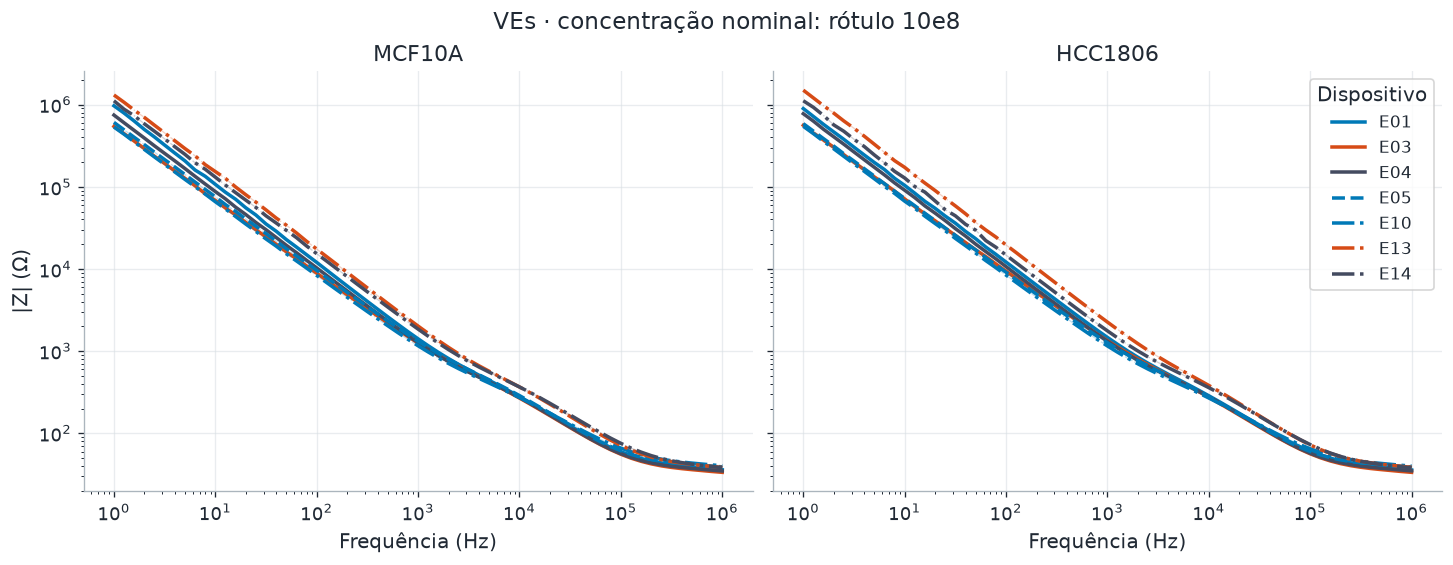

In [6]:
comparavel = analise[
    (analise.tipo == 'VEs')
    & (analise.concentracao_rotulo == CONCENTRACAO_COMPARAVEL)
    & analise.linhagem.isin(['MCF10A', 'HCC1806'])
].copy()
assert not comparavel.empty, 'O rótulo escolhido não está presente nos dados.'
# Mantém somente dispositivos que têm as duas linhagens na condição escolhida.
n_linhagens = comparavel.groupby('dispositivo').linhagem.nunique()
comparavel = comparavel[comparavel.dispositivo.isin(n_linhagens[n_linhagens == 2].index)]
assert comparavel.dispositivo.nunique() >= 2, 'São necessários ao menos dois dispositivos.'
display(comparavel.drop_duplicates('aplicacao').groupby(
    ['dispositivo', 'linhagem']).size().rename('grupos').to_frame())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, linhagem in zip(axs, ['MCF10A', 'HCC1806']):
    s = comparavel[comparavel.linhagem == linhagem]
    for dev, g in s.groupby('dispositivo'):
        cor, linha, _ = estilos_dispositivo[dev]
        for _, a in g.groupby('aplicacao'):
            a = a.sort_values('frequencia_hz')
            ax.loglog(a.frequencia_hz, a.modulo_ohm, color=cor, ls=linha, alpha=.25, lw=.8)
        mediana = g.groupby('frequencia_hz').modulo_ohm.median().sort_index()
        ax.loglog(mediana.index, mediana, color=cor, ls=linha, lw=2.1, label=dev)
    ax.set(title=linhagem, xlabel='Frequência (Hz)')
axs[0].set_ylabel('|Z| (Ω)')
axs[-1].legend(title='Dispositivo', fontsize=10)
fig.suptitle(f'VEs · concentração nominal: rótulo {CONCENTRACAO_COMPARAVEL}')
plt.show()

## 2. Cada aplicação em frequências selecionadas

Cada ponto representa a mediana das leituras de um grupo na frequência indicada. As três frequências são exemplos editáveis de regiões baixa, intermediária e alta do espectro, e não médias de bandas. Usa-se o ponto medido mais próximo somente quando o desvio é de até 2%; não há extrapolação. O deslocamento horizontal serve apenas para separar visualmente os pontos.

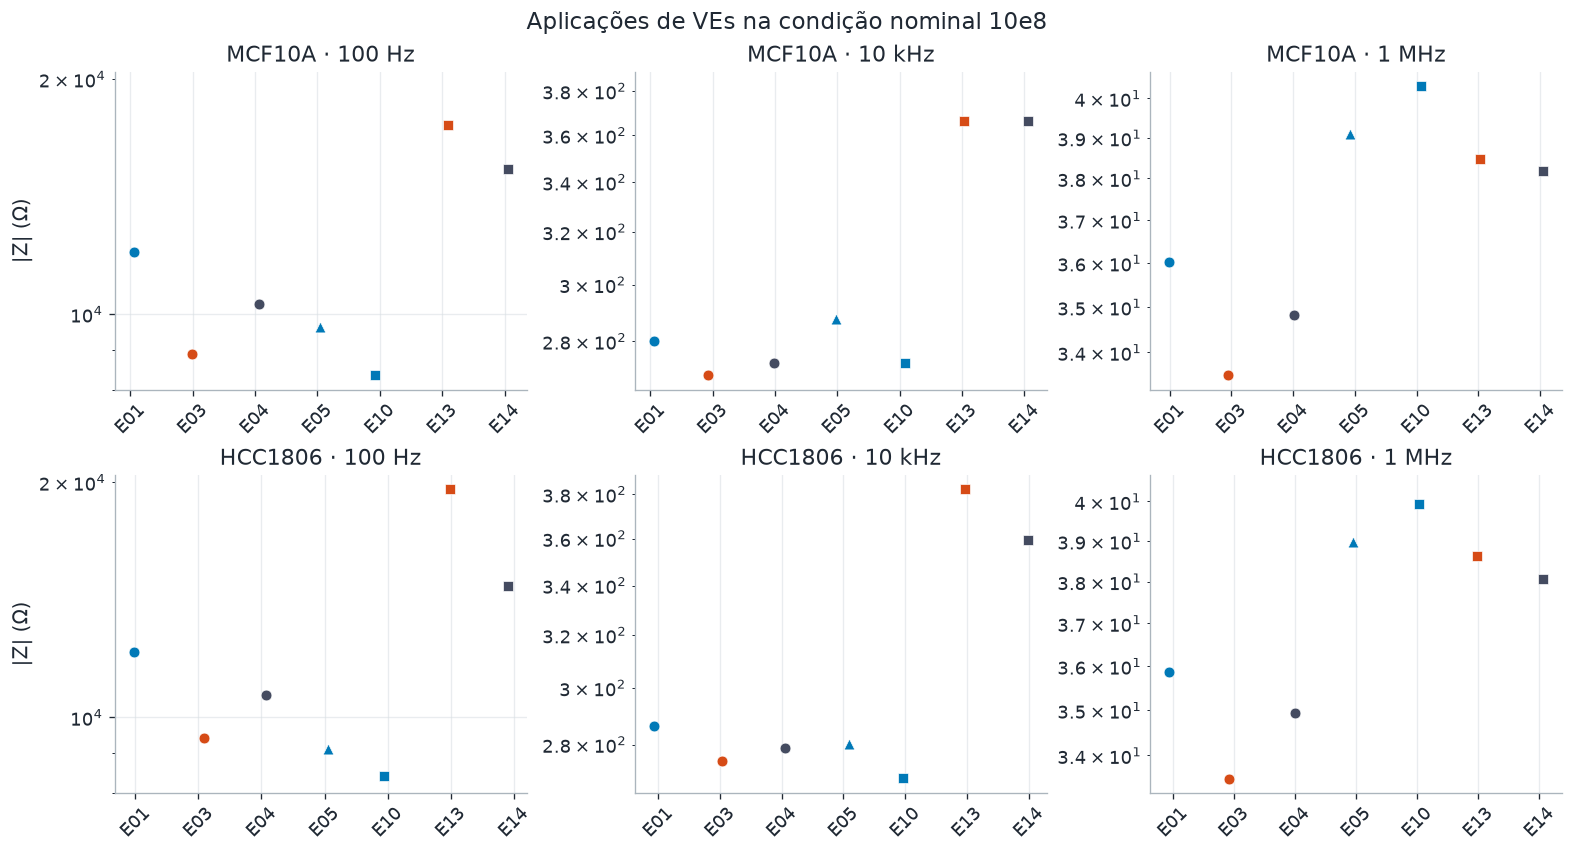

menor_mediana_ohm  maior_mediana_ohm  razao_max_min
linhagem alvo_hz                                                       
HCC1806  100.0            8419.766467       19585.548696       2.326139
         10000.0           268.970644         382.374184       1.421621
         1000000.0          33.501008          39.940390       1.192215
MCF10A   100.0            8345.671417       17474.972871       2.093897
         10000.0           268.639855         366.640835       1.364804
         1000000.0          33.505399          40.313266       1.203187

In [7]:
def selecionar_frequencias(dados, alvos):
    linhas = []
    for app, g in dados.groupby('aplicacao', sort=True):
        for alvo in alvos:
            i = (np.log10(g.frequencia_hz) - np.log10(alvo)).abs().idxmin()
            linha = g.loc[i].to_dict()
            if abs(linha['frequencia_hz'] / alvo - 1) > .02:
                raise ValueError(f'{app}: não há frequência medida próxima de {alvo:g} Hz.')
            linha['alvo_hz'] = alvo
            linhas.append(linha)
    return pd.DataFrame(linhas)

def rotulo_freq(f):
    return f'{f / 1e6:g} MHz' if f >= 1e6 else f'{f / 1e3:g} kHz' if f >= 1e3 else f'{f:g} Hz'

pontos = selecionar_frequencias(comparavel, FREQUENCIAS_HZ)
ordem = sorted(comparavel.dispositivo.unique())
fig, axs = plt.subplots(2, len(FREQUENCIAS_HZ), figsize=(13, 7), sharey='col', squeeze=False)
rng = np.random.default_rng(42)
for linha, linhagem in enumerate(['MCF10A', 'HCC1806']):
    for coluna, freq in enumerate(FREQUENCIAS_HZ):
        ax = axs[linha, coluna]
        s = pontos[(pontos.linhagem == linhagem) & (pontos.alvo_hz == freq)]
        for x, dev in enumerate(ordem):
            g = s[s.dispositivo == dev]
            cor, _, marcador = estilos_dispositivo[dev]
            ax.scatter(x + rng.uniform(-.10, .10, len(g)), g.modulo_ohm,
                       color=cor, marker=marcador, s=42, edgecolors='white', linewidths=.4)
        ax.set_xticks(range(len(ordem)), ordem, rotation=45)
        ax.set_yscale('log')
        ax.set_title(f'{linhagem} · {rotulo_freq(freq)}')
        if coluna == 0:
            ax.set_ylabel('|Z| (Ω)')
fig.suptitle(f'Aplicações de VEs na condição nominal {CONCENTRACAO_COMPARAVEL}')
plt.show()

# Razão descritiva entre a maior e a menor mediana dos dispositivos.
medianas = pontos.groupby(['linhagem', 'alvo_hz', 'dispositivo']).modulo_ohm.median()
razoes = medianas.groupby(['linhagem', 'alvo_hz']).agg(['min', 'max'])
razoes['razao_max_min'] = razoes['max'] / razoes['min']
display(razoes.rename(columns={'min': 'menor_mediana_ohm', 'max': 'maior_mediana_ohm'}))

## 3. Visão geral: PBS, controles e VEs

Aqui entram todas as campanhas e concentrações disponíveis, incluindo o E07. Cada ponto continua sendo um grupo de aplicação. Cores e formas indicam o tipo de material e a linhagem das VEs quando identificada; o eixo horizontal identifica o dispositivo. A tabela anterior informa o número de aplicações por grupo.

Este gráfico mostra as faixas observadas do conjunto histórico. Como as condições diferem entre dispositivos, ele não isola um efeito causal do dispositivo. A dispersão dentro de um dispositivo também mistura aplicações, concentrações e campanhas; a repetibilidade das leituras da mesma gota será avaliada separadamente.

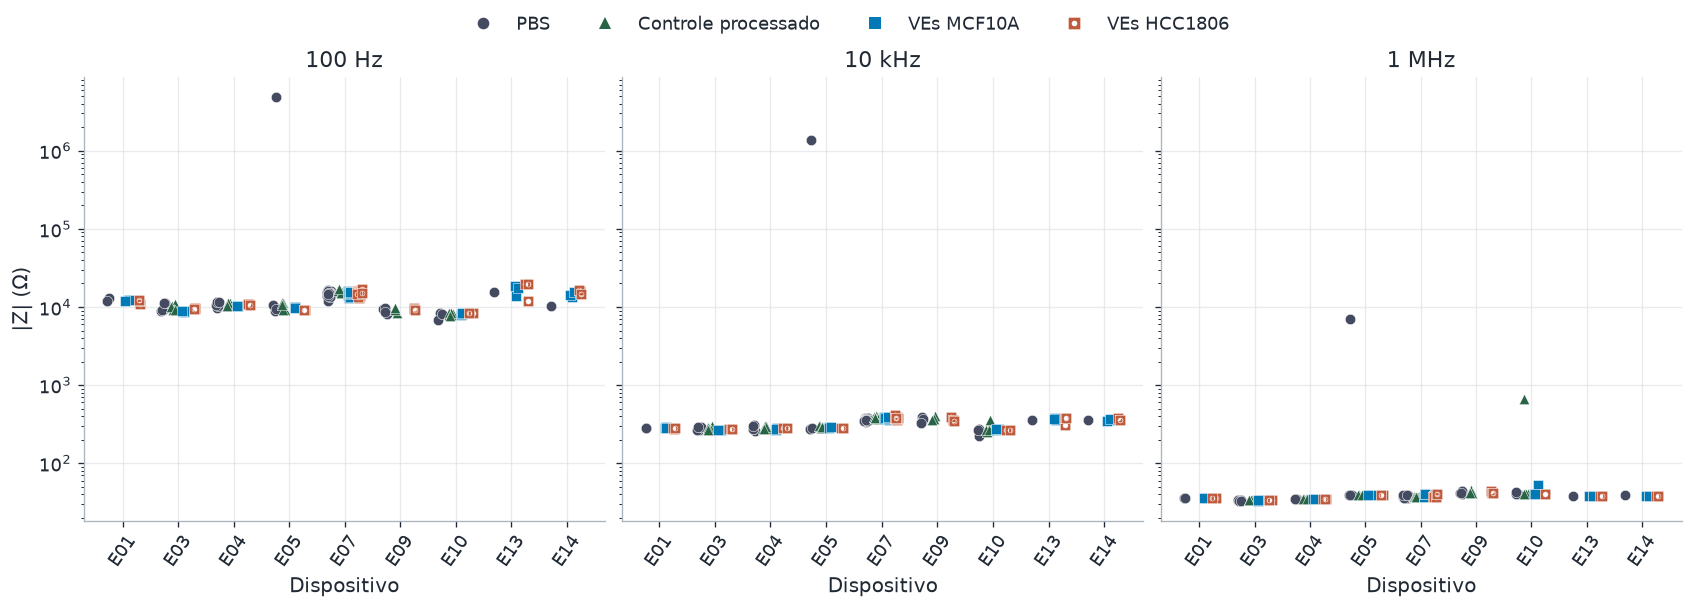

In [8]:
pontos_gerais = selecionar_frequencias(analise, FREQUENCIAS_HZ)
# O círculo tem orientação inversa à do quadrado e abre um furo no marcador.
quadrado_vazado = MarkerPath.make_compound_path(
    MarkerPath.unit_rectangle().transformed(Affine2D().translate(-.5, -.5)),
    MarkerPath.unit_circle().transformed(Affine2D().scale(.24, -.24)),
)
rotulos_ves = {'MCF10A': 'VEs MCF10A', 'HCC1806': 'VEs HCC1806'}
ves_sem_linhagem = 'VEs (linhagem não informada)'
estilos_material = {
    'PBS': (REFERENCIA, 'o'),
    'Controle processado': ('#276445', '^'),
    'VEs MCF10A': (AZUL, 's'),
    'VEs HCC1806': ('#BF5A3C', quadrado_vazado),
}
if not analise.loc[analise.tipo.eq('VEs'), 'linhagem'].isin(rotulos_ves).all():
    estilos_material[ves_sem_linhagem] = ('#78548F', 'D')
legenda_tipos = [
    Line2D([], [], marker=marcador, ls='', color=cor, label=rotulo,
           markeredgewidth=0, markersize=7)
    for rotulo, (cor, marcador) in estilos_material.items()
]


def plotar_aplicacoes(ax, dados, coluna_y, ordem, rng, tamanho=39):
    serie = dados.tipo.mask(
        dados.tipo.eq('VEs'), dados.linhagem.map(rotulos_ves).fillna(ves_sem_linhagem)
    )
    centro = (len(estilos_material) - 1) / 2
    for x, dev in enumerate(ordem):
        for k, (rotulo, (cor, marcador)) in enumerate(estilos_material.items()):
            g = dados[(dados.dispositivo == dev) & (serie == rotulo)]
            pos = x + (k - centro) * .18 + rng.uniform(-.045, .045, len(g))
            ax.scatter(pos, g[coluna_y], color=cor, marker=marcador, s=tamanho,
                       edgecolors='white', linewidths=.3)


fig, axs = plt.subplots(1, len(FREQUENCIAS_HZ), figsize=(14, 5), sharey=True, squeeze=False)
rng = np.random.default_rng(42)
for ax, freq in zip(axs[0], FREQUENCIAS_HZ):
    s = pontos_gerais[pontos_gerais.alvo_hz == freq]
    plotar_aplicacoes(ax, s, 'modulo_ohm', devices, rng)
    ax.set_xticks(range(len(devices)), devices, rotation=55)
    ax.set_yscale('log')
    ax.set_title(rotulo_freq(freq))
    ax.set_xlabel('Dispositivo')
axs[0, 0].set_ylabel('|Z| (Ω)')
fig.legend(handles=legenda_tipos, loc='outside upper center', ncol=len(estilos_material), frameon=False)
plt.show()

## 4. Faixas espectrais: vários pontos por dispositivo

Esta figura amplia a ideia da Figura 24 do PDF (página 83 do arquivo): cada ponto é agora um grupo de aplicação, em vez de uma curva por linhagem. Mostramos valores absolutos de |Z| para não presumir pareamento com referências de PBS.

Em cada aplicação, calculamos primeiro a mediana das leituras em cada frequência e depois a média aritmética dessas impedâncias dentro da banda. Os intervalos não se sobrepõem; o limite superior só é incluído na última banda. A média é sobre os pontos adquiridos, sem interpolação. A tabela informa a cobertura de frequências: médias com grades diferentes não devem ser interpretadas como estritamente equivalentes.

A primeira figura mostra todos os valores em escala logarítmica. Na ampliação, o eixo Y de cada painel usa escala linear e vai de pouco abaixo do mínimo até 15% acima do percentil 98 da banda. Os valores acima do recorte aparecem na figura completa.

A visão geral reúne concentrações e campanhas distintas; serve para observar faixas e sobreposições, sem isolar a causa das diferenças. Para repetir com a condição nominal comparável, troque `fonte_bandas = analise` por `fonte_bandas = comparavel`.

,,pontos,min_n_freq,max_n_freq,menor_hz,maior_hz,grades_distintas
dispositivo,banda,,,,,,
E01,1–10 Hz,8,10,10,1.0,7.9433,1
E03,1–10 Hz,17,10,10,1.0,7.9433,1
E04,1–10 Hz,17,10,10,1.0,7.9433,1
E05,1–10 Hz,16,10,10,1.0,7.9433,1
E07,1–10 Hz,79,10,10,1.0,7.9433,1
E09,1–10 Hz,11,10,10,1.0,7.9433,1
E10,1–10 Hz,15,10,10,1.0,7.9433,1
E13,1–10 Hz,7,10,10,1.0,7.9433,1
E14,1–10 Hz,7,10,10,1.0,7.9433,1


Confira também se as grades coincidem entre dispositivos antes de comparar médias de bandas.


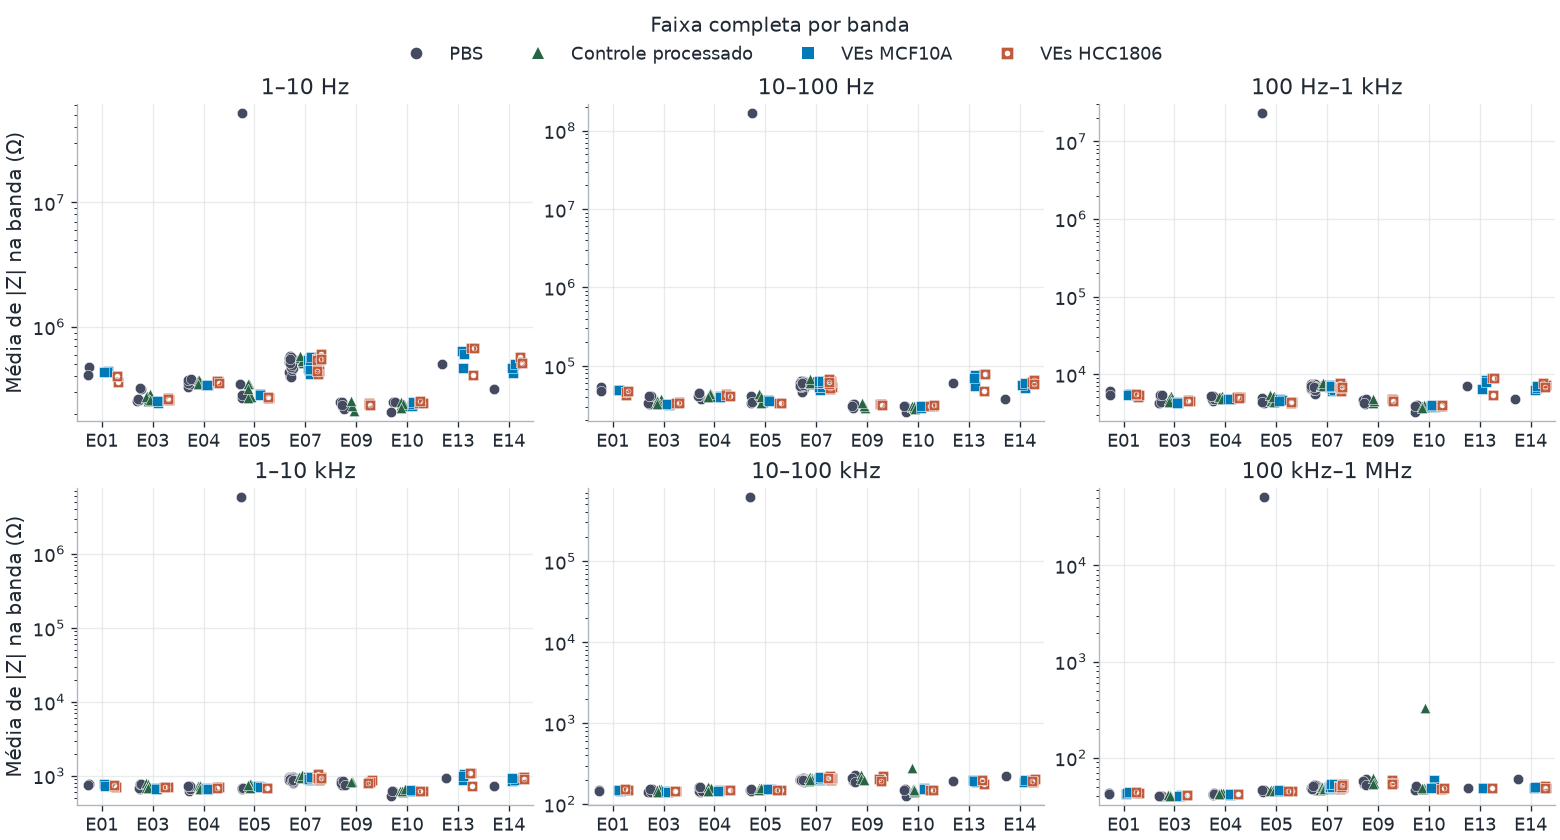

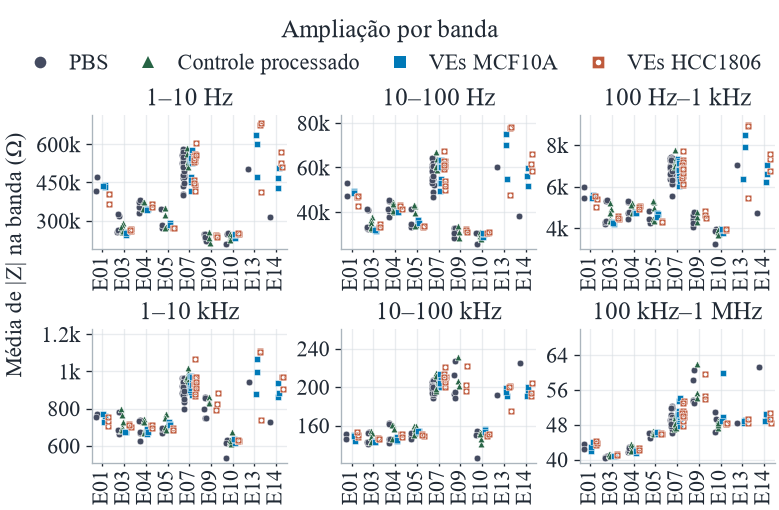

In [10]:
fonte_bandas = analise
bandas = [(1, 10, '1–10 Hz'), (10, 100, '10–100 Hz'),
          (100, 1_000, '100 Hz–1 kHz'), (1_000, 10_000, '1–10 kHz'),
          (10_000, 100_000, '10–100 kHz'), (100_000, 1_000_000, '100 kHz–1 MHz')]
resumos_bandas = []
for i, (lo, hi, nome) in enumerate(bandas):
    freq = fonte_bandas.frequencia_hz
    mask = (freq >= lo) & ((freq <= hi) if i == len(bandas) - 1 else (freq < hi))
    b = (fonte_bandas[mask].groupby(meta_cols, observed=True, as_index=False)
         .agg(media_modulo_ohm=('modulo_ohm', 'mean'),
              n_frequencias=('frequencia_hz', 'nunique'),
              menor_hz=('frequencia_hz', 'min'), maior_hz=('frequencia_hz', 'max'),
              grade_hz=('frequencia_hz', lambda x: tuple(sorted(x.unique())))))
    b['banda'] = nome
    resumos_bandas.append(b)
dados_bandas = pd.concat(resumos_bandas, ignore_index=True)
display(dados_bandas.groupby(['dispositivo', 'banda'], sort=False).agg(
    pontos=('aplicacao', 'nunique'), min_n_freq=('n_frequencias', 'min'),
    max_n_freq=('n_frequencias', 'max'), menor_hz=('menor_hz', 'min'),
    maior_hz=('maior_hz', 'max'), grades_distintas=('grade_hz', 'nunique')))
print('Confira também se as grades coincidem entre dispositivos antes de comparar médias de bandas.')

def plotar_bandas(ampliado=False):
    tamanho_figura = (16.5 / 2.54, 10.8 / 2.54) if ampliado else (13, 7)
    fig, axs = plt.subplots(2, 3, figsize=tamanho_figura, sharex=True)
    from matplotlib.ticker import EngFormatter

    rng = np.random.default_rng(42)
    ordem_bandas = sorted(fonte_bandas.dispositivo.unique())
    for ax, (_, _, banda) in zip(axs.flat, bandas):
        s = dados_bandas[dados_bandas.banda == banda]
        valores = s.media_modulo_ohm
        plotar_aplicacoes(ax, s, 'media_modulo_ohm', ordem_bandas, rng, tamanho=16 if ampliado else 39)

        ax.set_xticks(range(len(ordem_bandas)), ordem_bandas)
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_xlim(-.48, len(ordem_bandas) - .52)
        if ampliado:
            superior = valores.quantile(.98) * 1.15
            inferior = valores.min() - .04 * (superior - valores.min())
            ax.set_ylim(inferior, superior)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_formatter(EngFormatter(places=None, sep=''))
            ax.tick_params(axis='x', rotation=90, length=2, pad=2)
        else:
            ax.set_yscale('log')
            ax.margins(y=.03)
        ax.set_title(banda)

    if ampliado:
        fig.supylabel('Média de |Z| na banda (Ω)')
        fig.legend(handles=legenda_tipos, loc='outside upper center', ncol=len(estilos_material),
                   frameon=False, title='Ampliação por banda',
                   handletextpad=.35, columnspacing=.85)
        fig.savefig(RAIZ / 'imagens_prontas' / 'ampliacao_por_banda.pdf')
    else:
        for ax in axs[:, 0]:
            ax.set_ylabel('Média de |Z| na banda (Ω)')
        fig.legend(handles=legenda_tipos, loc='outside upper center', ncol=len(estilos_material),
                   frameon=False, title='Faixa completa por banda')
    plt.show()


plotar_bandas()
with plt.rc_context({'font.family': 'Times New Roman', 'pdf.fonttype': 42,
        'axes.titlesize': 15, 'axes.labelsize': 14, 'figure.labelsize': 14,
        'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13,
        'legend.title_fontsize': 15}):
    plotar_bandas(ampliado=True)

## Como usar estes resultados no TCC

**Metodologia:** descrever a investigação como uma sequência de decisões: avaliação inicial de múltiplos dispositivos; comparação das respostas; escolha de um único dispositivo para as etapas seguintes; avaliação da repetibilidade no E07; definição de leituras por aplicação; treinamento e teste final. Datas, critérios de escolha e ordem efetiva precisam ser confirmados no registro experimental.

**Resultados:** usar os gráficos 1 e 2 para discutir diferenças entre dispositivos em condições nominais comparáveis. Os gráficos 3 e 4 contextualizam o conjunto histórico e as faixas de PBS, controle e VEs. A razão entre medianas quantifica a amplitude observada; não é um teste de significância nem uma estimativa de reprodutibilidade controlada.

**Ligação com o texto atual:** o PDF já apresenta a sequência de desenvolvimento na seção metodológica, a comparação por bandas na Figura 24 e uma avaliação Gaussian Naive Bayes por eletrodo na Figura 27. Não reproduzimos aqui o desempenho reportado sem reconstruir o protocolo. O texto atual usa 18 aplicações no desenvolvimento principal; o inventário das cinco campanhas reúne 30 aplicações de VEs no E07. São recortes diferentes, cuja definição deverá ficar explícita na revisão.

**Conclusão que ainda não cabe nesta etapa:** afirmar que as diferenças causaram uma queda de desempenho do classificador. Isso exige uma análise posterior com validação por dispositivo e agrupamento das leituras da mesma aplicação para evitar vazamento entre treino e teste.

Antes de transformar o texto em afirmações definitivas, conferir a notação de concentração dos arquivos, os blocos do E09 e a comparabilidade entre lotes/campanhas. Os dados do E07 incluem 30 aplicações de VEs nas cinco campanhas; a separação efetiva entre treinamento e validação deverá ser definida no notebook específico, preservando o teste final.